# Band-aligned CTL summary — `plot_multi_mat_ctl`

`plot_multi_mat_ctl` puts the transition levels of several defects in one or more materials on a single band-alignment diagram:

- Each material is a block of columns, one column per defect.
- VB (green) and CB (orange) shading is placed using each material's conduction band offset. Faded strips show the cell-to-cell spread of the band edges.
- Each thermodynamic transition is coloured by charge state. With one site it is a single line; with several sites/cells it is a bar showing **min / mean / max** across sites.
- Transitions bypassed by a negative-U level can be shown as faint dashed marks.
- Optional horizontal Fermi level guides.

CTLs are calculated per site, against that site's own cell. They are only collected into a distribution after that, so charge states from different sites are never mixed.

> The crystalline HfO$_2$ data are the same as in `plot_ctl.ipynb`. The amorphous data and the SiO$_2$ values are **illustrative only** (see `data/make_example_data.py`).

In [1]:
import csv
from cp2k_utils.ctl import (Defect, Cell, Material, CTL, FermiLevel, StyleOptions,
                            load_defects_csv, plot_multi_mat_ctl)

## 1. Single CTL values: crystalline hosts

The simplest case is one cell with one site per defect, like the input to `plot_ctl`. Each transition then has exactly one value and is drawn as a **single line**, not a range bar.

Here the crystalline HfO$_2$ defects from `plot_ctl.ipynb` are reused. The only extra things needed are `material` on each `Defect` and a `Material` holding the one `Cell`.

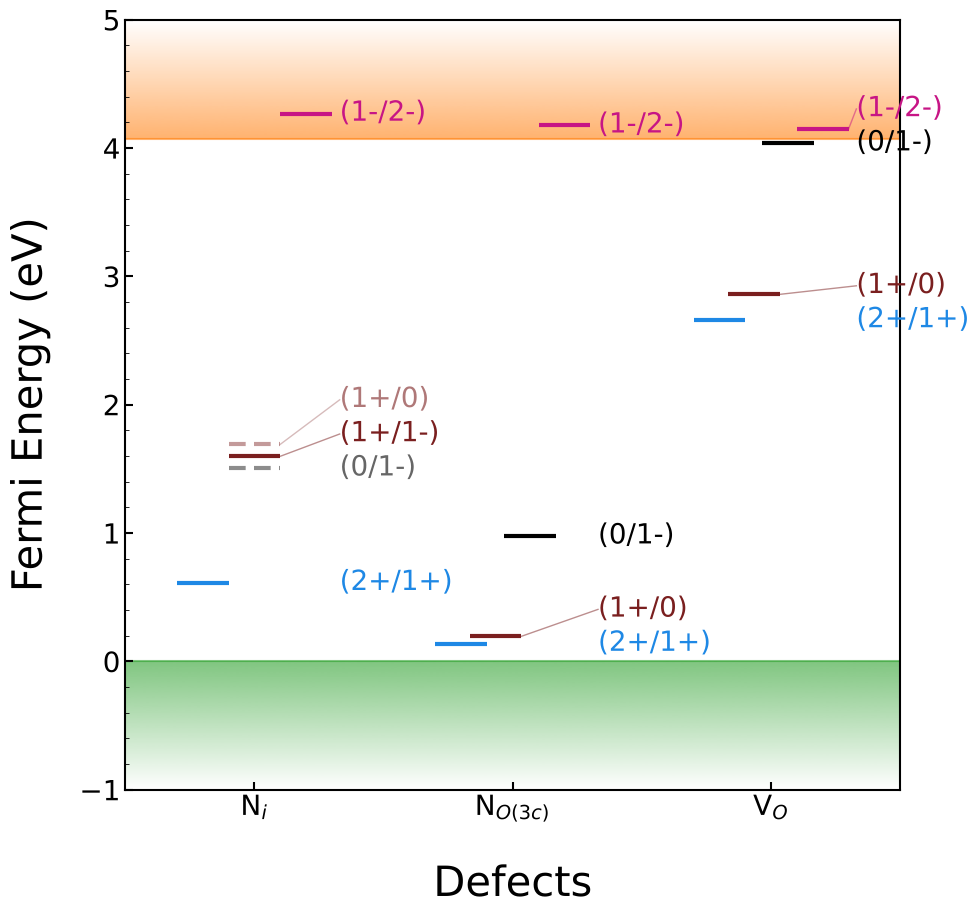

In [2]:
N = -19.82216306984949 / 2
O = -31.80451126833290 / 2

def hfo2(*args, **kw):
    return Defect(*args, material='c-HfO2', **kw)

crystal_defects = [
    hfo2('N',  2, -2615.18759465001131, N, 0.20648, 'i', '', 0, label='N_i'),
    hfo2('N',  1, -2614.87186971514484, N, 0.05162, 'i', '', 0, label='N_i'),
    hfo2('N',  0, -2614.52029755960666, N, 0.0,     'i', '', 0, label='N_i'),
    hfo2('N', -1, -2614.17935614371982, N, 0.05162, 'i', '', 0, label='N_i'),
    hfo2('N', -2, -2613.74063029902118, N, 0.20648, 'i', '', 0, label='N_i'),

    hfo2('N',  2, -2599.16786584031115, N, 0.20648, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    hfo2('N',  1, -2598.86955609518282, N, 0.05162, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    hfo2('N',  0, -2598.57295499858446, N, 0.0,     's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    hfo2('N', -1, -2598.25148415469221, N, 0.05162, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),
    hfo2('N', -2, -2597.81613103389191, N, 0.20648, 's', 'O3c', O, label='N_O3c', title='N$_{O(3c)}$'),

    hfo2('O',  2, -2589.39963503920580, 0, 0.20648, 'v', 'O3c', O, label='V_O3c'),
    hfo2('O',  1, -2589.00866444766143, 0, 0.05162, 'v', 'O3c', O, label='V_O3c'),
    hfo2('O',  0, -2588.61414089194932, 0, 0.0,     'v', 'O3c', O, label='V_O3c'),
    hfo2('O', -1, -2588.18012071979138, 0, 0.05162, 'v', 'O3c', O, label='V_O3c'),
    hfo2('O', -2, -2587.74580752241673, 0, 0.20648, 'v', 'O3c', O, label='V_O3c'),
]

c_hfo2 = Material('c-HfO2', title='m-HfO$_2$',
                  cells=[Cell('bulk', vbm=0.287532, cbm=0.437028, bulk=-2604.76801711694679)])

fig, ax, _ = plot_multi_mat_ctl(crystal_defects, [c_hfo2], style=StyleOptions(figsize=(10, 10)))

The dashed, faded marks for N$_i$ are the transitions through the skipped neutral state, because (1+/1-) is a negative-U transition. `StyleOptions(show_bypassed=False)` hides them.

### Several crystalline materials

Single values work the same way across materials. Below, the crystalline HfO$_2$ results are put next to a second material whose levels are supplied directly as `CTL` objects (see section 4). Its `Cell` only needs band edges; `bulk` is not used when every defect comes from `precomputed_ctls`.

> The second material's values are **made up** for the example.

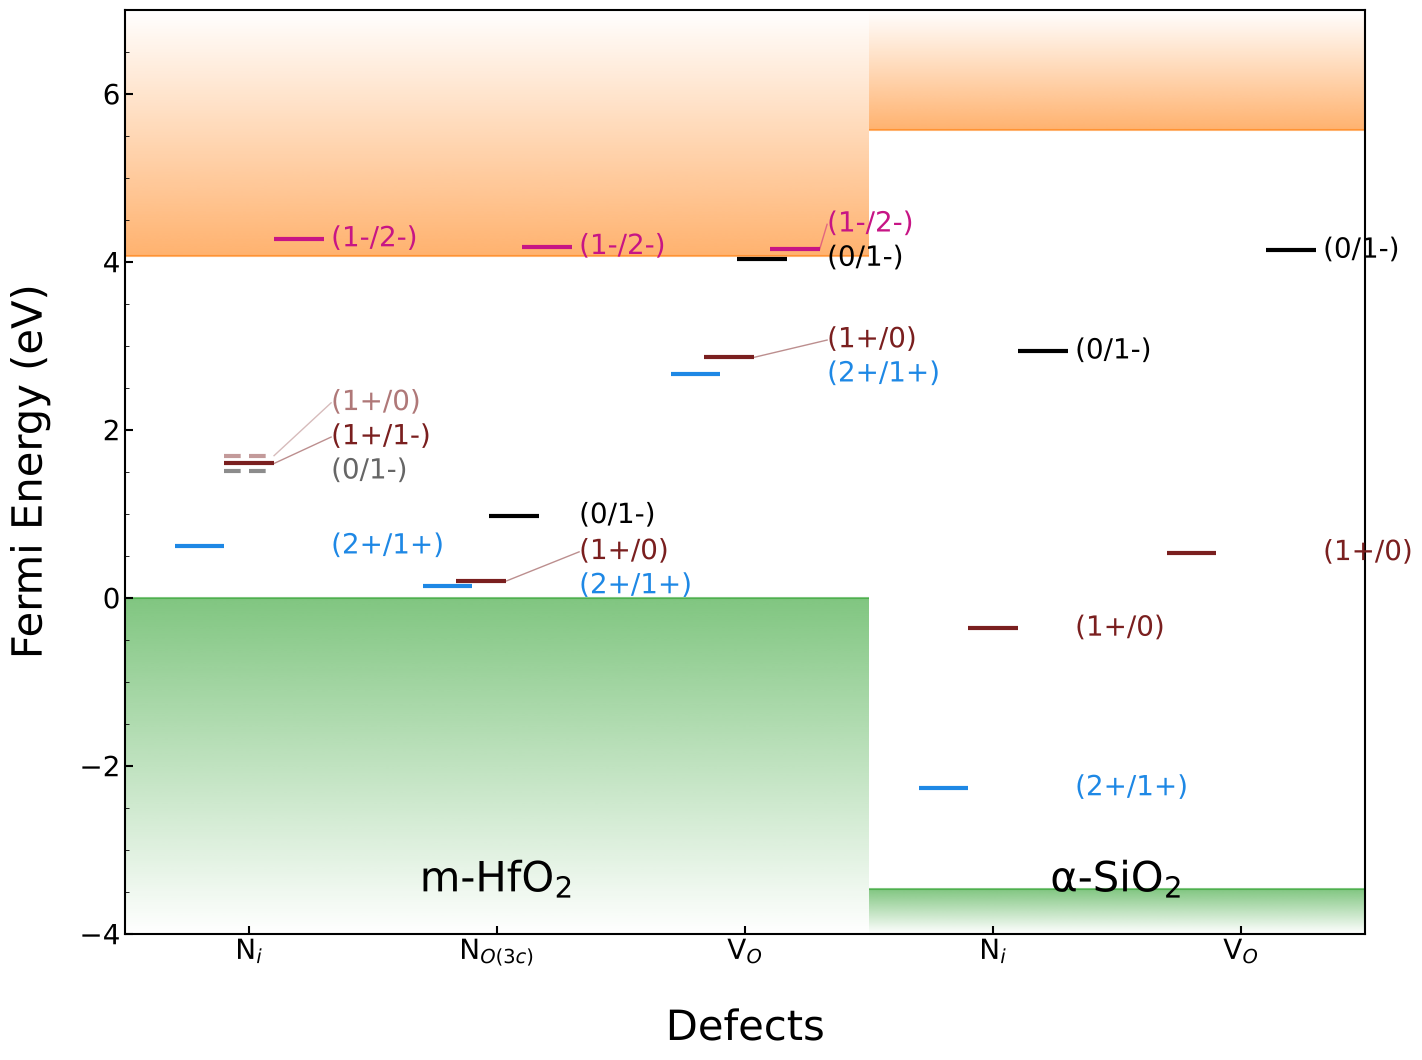

In [3]:
c_sio2 = Material('c-SiO2', title='α-SiO$_2$', offset=1.5,
                  cells=[Cell('bulk', vbm=0.2010, cbm=0.5330, bulk=0.0)])

sio2_ctls = {
    'c-SiO2': {
        'N$_i$':  [CTL('(2+/1+)', 1.2), CTL('(1+/0)', 3.1), CTL('(0/1-)', 6.4)],
        'V$_O$':  [CTL('(1+/0)', 4.0), CTL('(0/1-)', 7.6)],
    },
}

fig, ax, _ = plot_multi_mat_ctl(crystal_defects, [c_hfo2, c_sio2],
                                precomputed_ctls=sio2_ctls,
                                style=StyleOptions(figsize=(16, 12)))

## 2. Ranges over many sites: amorphous hosts

With several cells and sites per defect, each transition becomes a **distribution**. It is drawn as a bar showing the min, mean and max across sites.

### Materials and band offsets

Every `Defect` must have `material` set to the `name` of one of the `Material` objects.

`Material.offset` is the **conduction band offset (eV)** of that material compared with a reference material:
- The reference material has `offset=0`, and its VBM is drawn at y = 0.
- Each other material's CBM is placed `offset` eV above the reference CBM (negative is below). Its VBM is then placed using its own band gap.
- The reference is found automatically as the material with `offset == 0`. `reference='<name>'` chooses it explicitly; that material should also have `offset=0`.
- `title` changes how the material is labelled on the plot. Without it, digits in `name` are subscripted automatically (`HfO2` → HfO$_2$).

In [4]:
cells = {}
with open('data/amorphous_cells.csv') as fh:
    for row in csv.DictReader(fh):
        cells.setdefault(row['material'], []).append(
            Cell(row['cell_id'], float(row['vbm']), float(row['cbm']), float(row['bulk'])))

materials = [
    Material('HfO2', title='a-HfO$_2$', cells=cells['HfO2'], offset=0.0),
    Material('SiO2', title='a-SiO$_2$', cells=cells['SiO2'], offset=1.5),   # CB 1.5 eV above HfO2's
]
for m in materials:
    print(f'{m.name}: gap {m.mean_gap_eV:.2f} eV, VBM spread {[round(x, 2) for x in m.vbm_spread_eV]} eV')

defects = load_defects_csv('data/amorphous_defects.csv')

HfO2: gap 4.07 eV, VBM spread [7.76, 7.89] eV
SiO2: gap 9.03 eV, VBM spread [5.4, 5.47] eV


### Basic plot

| argument | default | |
|---|---|---|
| `fermi_lines` | `None` | a number, a `FermiLevel`, or a list of `FermiLevel`, on the displayed axis |
| `reference` | `None` | name of the reference material (VBM at y = 0) |
| `precomputed_ctls` | `None` | add CTLs from elsewhere (section 4) |
| `xlabel` | `True` | draw the 'Defects' x-axis label |
| `style` | `None` | `StyleOptions` |
| `save`, `filename` | `False`, `'Multi_Mat_CTLs.png'` | |
| `show` | `True` | |

It returns `(fig, ax, distributions)`.

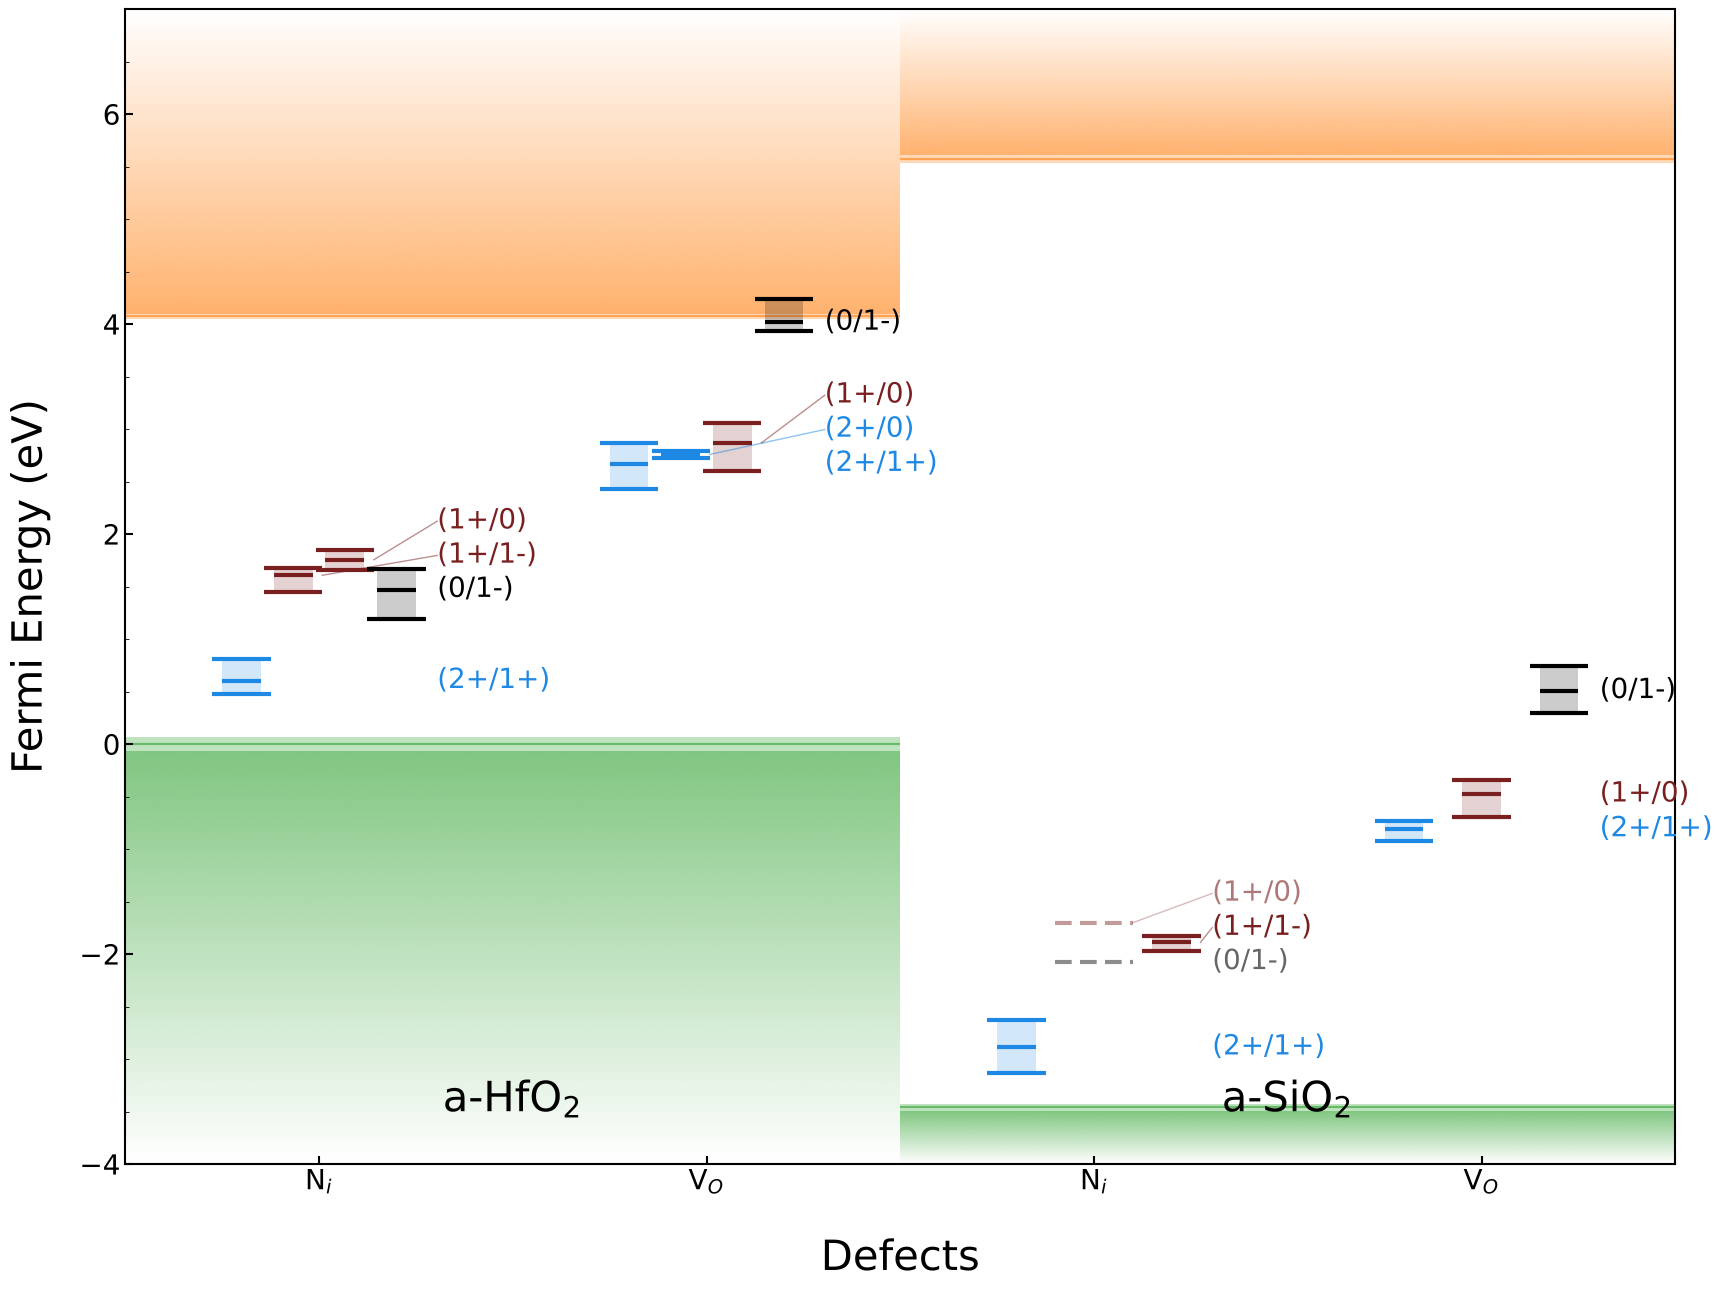

In [5]:
fig, ax, dist = plot_multi_mat_ctl(defects, materials)

`distributions[material][defect][transition]` holds the per-site values (eV above that material's VBM), so you can analyse them directly:

In [6]:
import numpy as np
for mat, dmap in dist.items():
    for dname, trans in dmap.items():
        for tr, entry in trans.items():
            v = np.array(entry['values'])
            print(f"{mat:5} {dname:4} {tr:>8} {entry['kind']:8}  mean {v.mean():5.2f}  range {v.min():5.2f}-{v.max():5.2f} eV  (n={len(v)})")

HfO2  N_i   (2+/1+) thermo    mean  0.60  range  0.48- 0.81 eV  (n=9)
HfO2  N_i   (1+/1-) thermo    mean  1.61  range  1.45- 1.68 eV  (n=8)
HfO2  N_i    (1+/0) thermo    mean  1.76  range  1.66- 1.85 eV  (n=9)
HfO2  N_i    (0/1-) thermo    mean  1.47  range  1.19- 1.67 eV  (n=9)
HfO2  V_O   (2+/1+) thermo    mean  2.67  range  2.43- 2.87 eV  (n=9)
HfO2  V_O    (1+/0) thermo    mean  2.87  range  2.60- 3.06 eV  (n=9)
HfO2  V_O    (0/1-) thermo    mean  4.01  range  3.94- 4.24 eV  (n=9)
HfO2  V_O    (2+/0) thermo    mean  2.76  range  2.73- 2.79 eV  (n=2)
SiO2  N_i   (2+/1+) thermo    mean  0.57  range  0.32- 0.83 eV  (n=6)
SiO2  N_i   (1+/1-) thermo    mean  1.57  range  1.48- 1.63 eV  (n=6)
SiO2  N_i    (1+/0) bypassed  mean  1.76  range  1.60- 1.84 eV  (n=6)
SiO2  N_i    (0/1-) bypassed  mean  1.38  range  1.32- 1.47 eV  (n=6)
SiO2  V_O   (2+/1+) thermo    mean  2.65  range  2.54- 2.73 eV  (n=6)
SiO2  V_O    (1+/0) thermo    mean  2.98  range  2.77- 3.12 eV  (n=6)
SiO2  V_O    (0/1-) 

## 3. Fermi levels and styling

`FermiLevel(label, energy, colour=None)` draws a dashed horizontal line. `energy` is on the displayed axis, so it is measured from the reference material's VBM.

`StyleOptions` fields that apply to this plot:

| option | default | |
|---|---|---|
| `figsize`, `title` | `(20, 15)`, `None` | |
| `legend`, `legend_fontsize` | `False`, `20` | legend of transitions + Fermi lines |
| `annotate_ctls`, `ctl_label_fontsize` | `True`, `20` | text labels next to each bar, spaced so they don't overlap |
| `leader_linewidth` | `1.0` | lines linking moved labels to their bars |
| `ctl_linewidth` | `3` | |
| `ctl_colour` | `None` | one colour for every transition instead of colouring by charge |
| `show_bypassed`, `bypassed_alpha`, `bypassed_linewidth` | `True`, `0.45`, `None` | |
| `band_edge_lines`, `band_alpha` | `True`, `0.6` | |
| `show_material_labels`, `mats_fontsize` | auto (only if >1 material), `30` | |
| `axes_fontsize`, `ticks_fontsize` | `30`, `20` | |

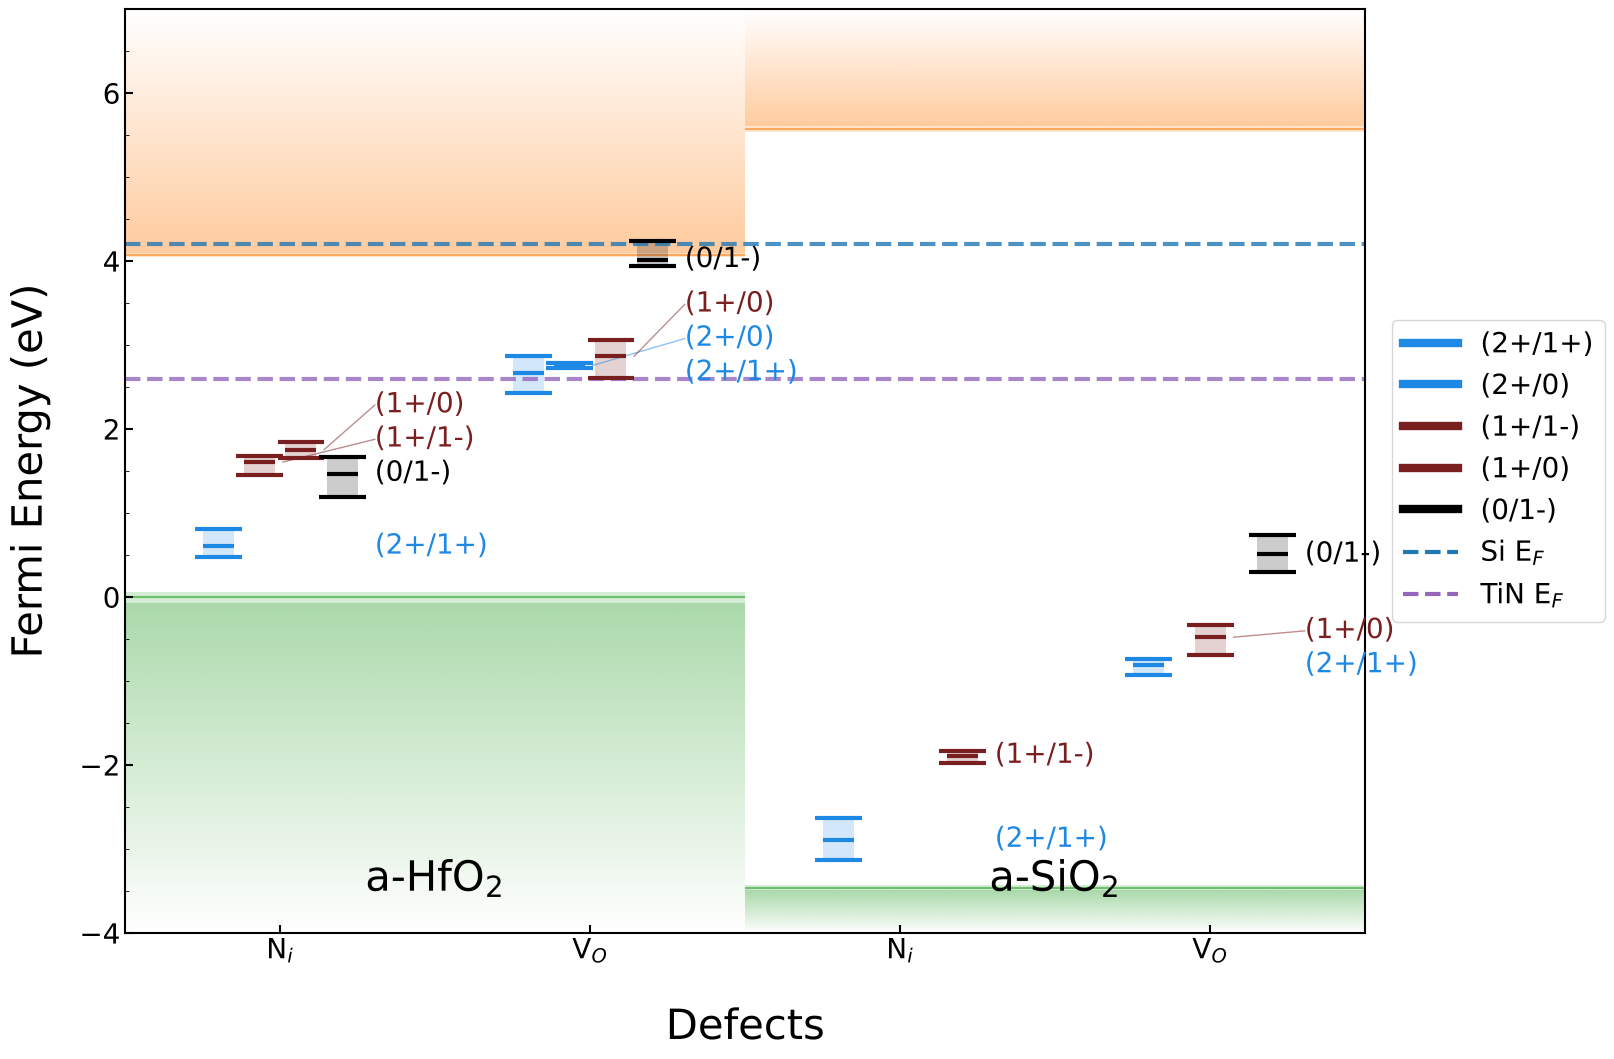

In [7]:
style = StyleOptions(
    figsize=(16, 12),
    legend=True,
    show_bypassed=False,
    band_alpha=0.4,
)

fermi = [
    FermiLevel('Si E$_F$', 4.2, colour='tab:blue'),
    FermiLevel('TiN E$_F$', 2.6, colour='tab:purple'),
]

fig, ax, _ = plot_multi_mat_ctl(defects, materials, fermi_lines=fermi, style=style, show=False)

# the returned fig/ax can be tweaked further, e.g. move the legend outside the axes
leg = ax.get_legend()
leg.set_loc('center left')
leg.set_bbox_to_anchor((1.01, 0.5))

### Single material

With only one material the material label is hidden automatically. Offsets are measured from the reference material, so a material plotted on its own should have `offset=0`.

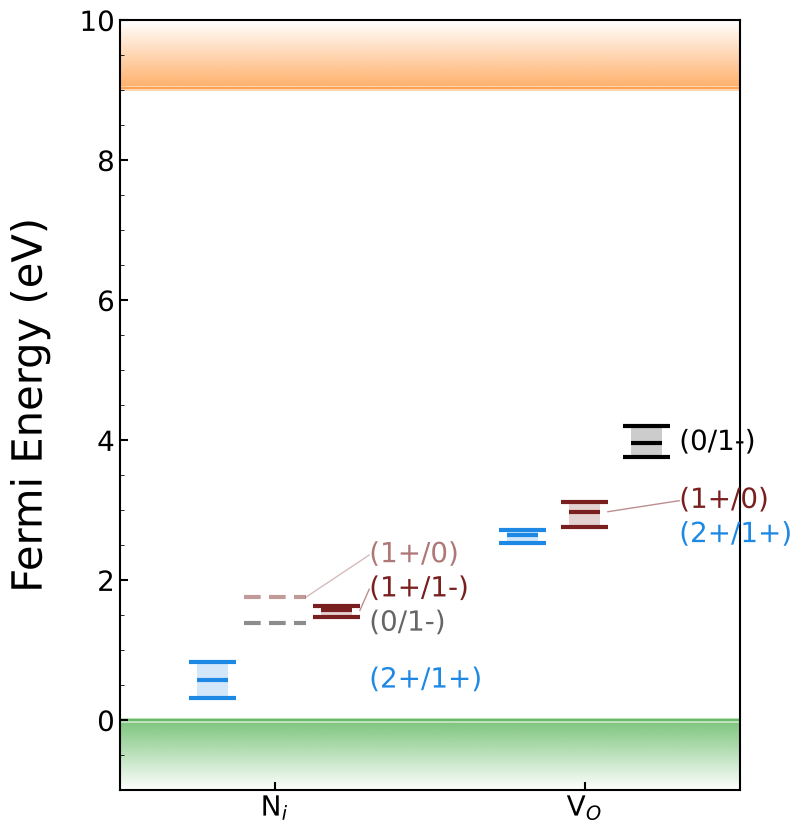

In [8]:
sio2 = Material('SiO2', title='a-SiO$_2$', cells=cells['SiO2'])   # offset defaults to 0
sio2_only = [d for d in defects if d.material == 'SiO2']

fig, ax, _ = plot_multi_mat_ctl(sio2_only, [sio2], style=StyleOptions(figsize=(8, 10)), xlabel=False)

## 4. Adding CTLs calculated elsewhere

`precomputed_ctls` lets you include transition levels you did not compute from raw `Defect` energies, such as literature values or another code's output:

```python
{material_name: {defect_label: [CTL(...), ...]}}
```

`CTL(transition, energy, e_min=None, e_max=None)` gives the energy in eV above that material's VBM. Use the same `'(q/q\')'` notation as the computed ones so the colours match. If you also pass `e_min` / `e_max`, the CTL is drawn as a range bar.

> **Note:** the axis label for a precomputed-only defect currently comes from the dict key, so write it in the form you want displayed (LaTeX is fine).

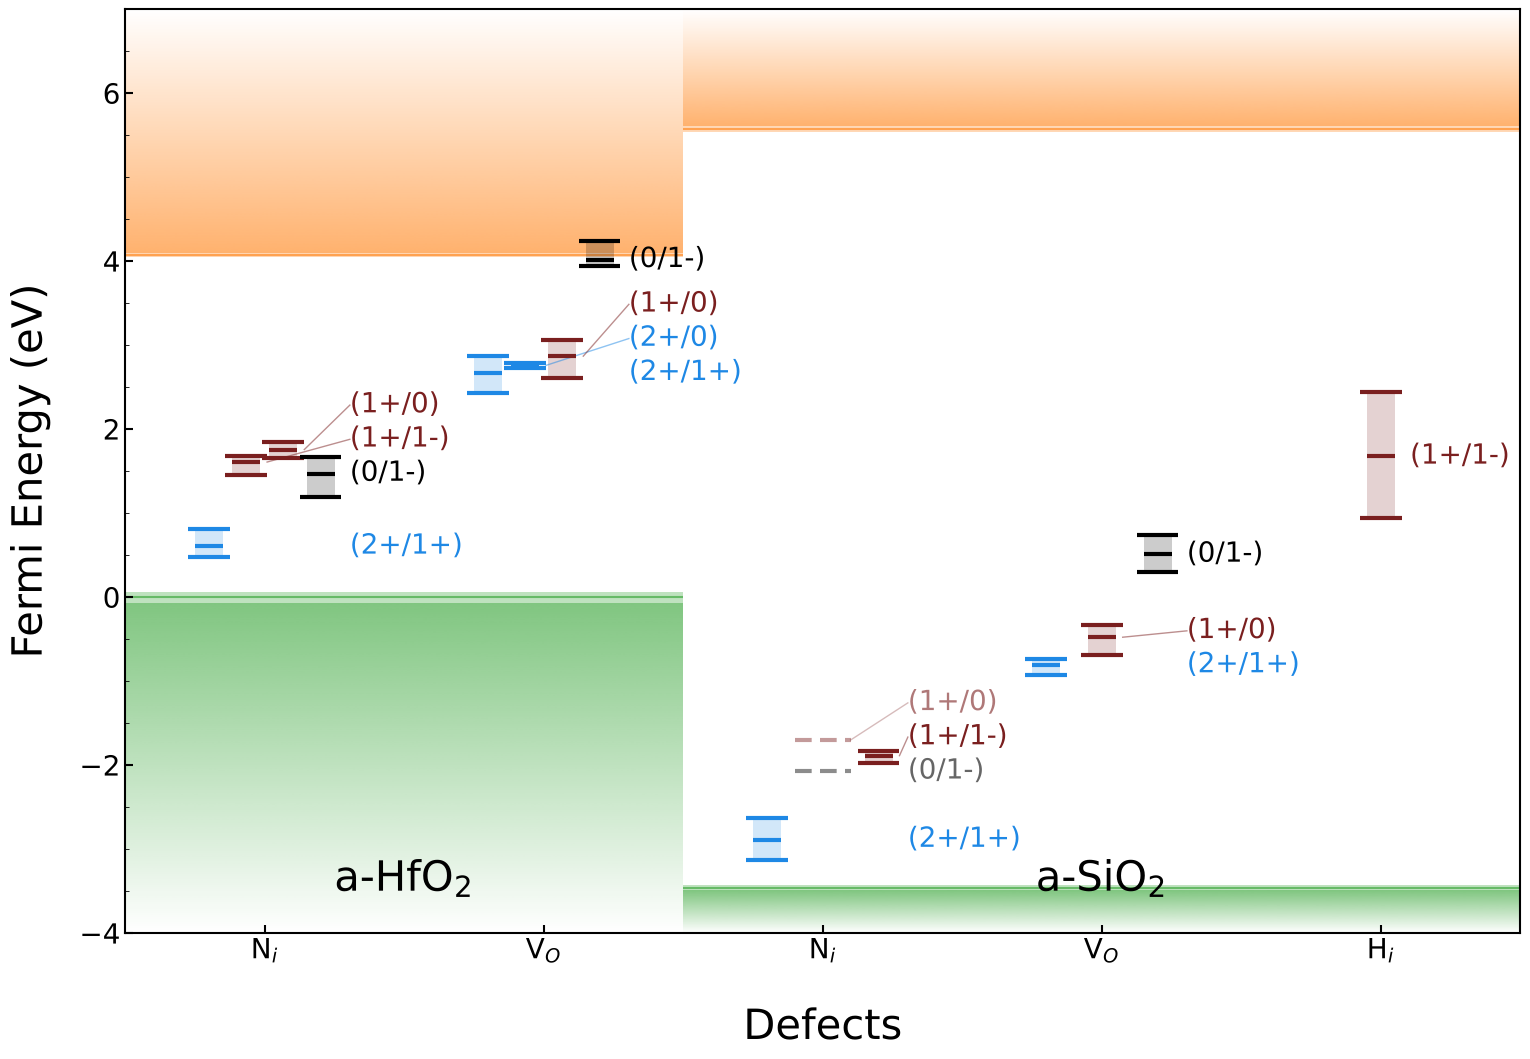

In [9]:
extra = {
    'SiO2': {
        'H$_i$': [CTL('(1+/1-)', 5.1, e_min=4.4, e_max=5.9)],
    },
}

fig, ax, _ = plot_multi_mat_ctl(defects, materials, precomputed_ctls=extra,
                                style=StyleOptions(figsize=(18, 12)))